# D²FC stabilization of an unstable equilibrium in a two-cell FitzHugh–Nagumo cardiac model

This notebook combines two papers:

- **Hattoum et al.**, *A Heterogeneous FitzHugh–Nagumo Model Exhibiting Local and Regional Dynamics that Mimic Spontaneous Atrial Fibrillation* — specifically the two-cell (slow-recovery + fast-recovery) coupled model of §IV.B, whose bifurcation diagram (their Fig. 9) shows a saddle-focus equilibrium that, for $b_1 \gtrsim 5.614$, has a stable "trapped" non-physiologic limit cycle born around it via a reverse period-doubling bifurcation (their Fig. 10).
- **Pastor & González**, *Delayed full feedback control with difference between two past states and periodic gain for stabilization and chaos control* — the **D²FC** scheme, $u(t) = K(t)\,[x(t-2\tau)-x(t-\tau)]$ with an act-and-wait periodic gain $K(t)$, and its "controlling chaos" strategy (their §5) for driving a trajectory onto an unstable equilibrium embedded in a self-sustained oscillation.

**What this notebook does:** finds the equilibria of the two-cell FHN system at $b_1=5.7$, identifies the unstable saddle-focus equilibrium embedded in the trapped oscillation, builds a D²FC gain matrix $K$ from the real Jordan decomposition (D²FC §3.2, the $n_r=0,\,n_c=2$ case), and simulates the free vs. D²FC-controlled system.

> **Caveat (please read):** D²FC's rigorous theory (Thm. 1 of the D²FC paper) stabilizes *hyperbolic equilibrium points*, not periodic orbits directly — literal UPO stabilization is listed by its authors as *future work* with an untested formula. What's implemented below is the equilibrium-stabilization strategy the D²FC paper itself uses for "chaos control" (§5), applied here to an equilibrium embedded in the FHN paper's pathological oscillation, rather than to the orbit itself.


In [1]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Two-cell FHN model (Hattoum et al., §IV.B)

State $x=(v_1,w_1,v_2,w_2)$: cell 1 is slow-recovery, cell 2 is fast-recovery.

In [2]:
# Cell parameters (paper 1, Section IV.B)
sigma1, eps1, a1, c1 = 0.6, 0.004, 0.01, 1.0     # slow-recovery cell
sigma2, eps2, a2, c2, b2 = 1.6, 0.008, 0.02, 1.0, 2.9  # fast-recovery cell
g = 0.028  # coupling conductance

def f(x, b1):
    v1, w1, v2, w2 = x
    dv1 = sigma1 * (v1*(v1-a1)*(c1-v1) - w1 + g*(v2-v1))
    dw1 = eps1 * (v1 - b1*w1)
    dv2 = sigma2 * (v2*(v2-a2)*(c2-v2) - w2 + g*(v1-v2))
    dw2 = eps2 * (v2 - b2*w2)
    return np.array([dv1, dw1, dv2, dw2])

b1 = 5.7  # solidly past the reverse period-doubling bifurcation (~5.614) -> trapped oscillation regime

### 1.1 Find the equilibria

In [3]:
def find_equilibria(b1, guesses):
    sols = []
    for g0 in guesses:
        sol, info, ier, msg = fsolve(f, g0, args=(b1,), full_output=True, xtol=1e-13)
        if ier == 1 and np.max(np.abs(f(sol, b1))) < 1e-9:
            if not any(np.allclose(sol, s, atol=1e-6) for s in sols):
                sols.append(sol)
    return sols

guesses = [
    [0,0,0,0],
    [0.7, 0.13, 0.7, 0.25],
    [0.75, 0.14, 0.75, 0.26],
    [0.5, 0.1, 0.5, 0.2],
    [0.3, 0.06, 0.3, 0.1],
    [0.9, 0.16, 0.9, 0.3],
]
sols = find_equilibria(b1, guesses)
for s in sols:
    print("equilibrium:", s)

equilibrium: [0. 0. 0. 0.]
equilibrium: [0.71457758 0.12536449 0.05962534 0.02056046]
equilibrium: [0.29594887 0.05192085 0.02236497 0.00771206]


### 1.2 Linearize at each equilibrium (numerical Jacobian) and check stability

In [4]:
def jacobian(fun, x, b1, h=1e-6):
    n = len(x)
    J = np.zeros((n,n))
    for j in range(n):
        dx = np.zeros(n); dx[j] = h
        J[:,j] = (fun(x+dx, b1) - fun(x-dx, b1)) / (2*h)
    return J

for s in sols:
    J = jacobian(f, s, b1)
    w, v = np.linalg.eig(J)
    print("="*60)
    print("equilibrium:", s)
    for lam in w:
        print(f"   {lam:.6f}   (Re={lam.real:.6f})")

equilibrium: [0. 0. 0. 0.]
   -0.050522+0.105754j   (Re=-0.050522)
   -0.050522-0.105754j   (Re=-0.050522)
   -0.022278+0.050737j   (Re=-0.022278)
   -0.022278-0.050737j   (Re=-0.022278)
equilibrium: [0.71457758 0.12536449 0.05962534 0.02056046]
   -0.050649+0.041127j   (Re=-0.050649)
   -0.050649-0.041127j   (Re=-0.050649)
   0.040100+0.091913j   (Re=0.040100)
   0.040100-0.091913j   (Re=0.040100)
equilibrium: [0.29594887 0.05192085 0.02236497 0.00771206]
   0.168825+0.000000j   (Re=0.168825)
   -0.010110+0.000000j   (Re=-0.010110)
   -0.016341+0.112180j   (Re=-0.016341)
   -0.016341-0.112180j   (Re=-0.016341)


This reproduces the paper's Fig. 9 description exactly:
- the **origin** is stable (all eigenvalues negative real part) — the healthy resting state;
- the **upper-branch** equilibrium ($v_1\approx0.715$) is a **saddle-focus**: one stable complex pair, one unstable complex pair — "remains unstable" throughout, as the paper states;
- the **lower-branch** equilibrium ($v_1\approx0.296$) has 1 unstable real eigenvalue + 3 stable — also matches the paper's count after its Hopf bifurcation at $b_1\approx4.811$.

We target the **upper-branch saddle-focus** — it's the equilibrium the trapped limit cycle (Fig. 10 of the FHN paper) is born around via the reverse period-doubling bifurcation.

In [5]:
xstar = np.array([0.71457758, 0.12536449, 0.05962534, 0.02056046])
A = jacobian(f, xstar, b1)
w, v = np.linalg.eig(A)
print("Jacobian at x*:\n", A)
print("\nEigenvalues:")
for lam in w:
    print(f"  {lam:.6f}")

Jacobian at x*:
 [[-0.07584999 -0.6         0.0168      0.        ]
 [ 0.004      -0.0228      0.          0.        ]
 [ 0.0448      0.          0.10075224 -1.6       ]
 [ 0.          0.          0.008      -0.0232    ]]

Eigenvalues:
  -0.050649+0.041127j
  -0.050649-0.041127j
  0.040100+0.091913j
  0.040100-0.091913j


## 2. D²FC control design (Pastor & González, §3.2)

$x^*$ has **two complex-conjugate eigenvalue pairs** and no real eigenvalues — this is the $n_r=0,\,n_c=2$ case of §3.2. For each pair $\lambda=\mu\pm i\omega$:
- if $\mathrm{Re}(\lambda)=\mu<0$ (already stable), the corresponding block of $\tilde K$ is left at $0_{2\times2}$ (no control needed);
- if $\mu>0$ (unstable), the block is $E=\begin{pmatrix}\epsilon^1 & -\epsilon^2\\ \epsilon^2 & \epsilon^1\end{pmatrix}$ with $\epsilon^1,\epsilon^2$ given by their Eq. (9), which places the closed-loop return-map multiplier for that block at a chosen $\rho\,e^{i\theta}$ ($\rho<1$).

### 2.1 Real Jordan decomposition $A = VJV^{-1}$

For a complex pair $\lambda=\mu+i\omega$ ($\omega>0$) with eigenvector $z=p+iq$, the real basis is $(p,\,-q)$ (sign chosen so the resulting block matches the paper's convention $\begin{pmatrix}\mu&-\omega\\\omega&\mu\end{pmatrix}$ — verified numerically below).

In [6]:
idx_used = set()
pairs = []
for i in range(len(w)):
    if i in idx_used or abs(w[i].imag) < 1e-9:
        continue
    for j in range(len(w)):
        if j != i and j not in idx_used and np.isclose(w[j], np.conj(w[i]), atol=1e-6):
            pairs.append((i, j)); idx_used.add(i); idx_used.add(j)
            break

V_cols, blocks = [], []
for (i, j) in pairs:
    lam, z = (w[i], v[:, i]) if w[i].imag > 0 else (w[j], v[:, j])
    mu, omega = lam.real, lam.imag
    p, q = z.real, -z.imag   # sign flip -> matches paper's [[mu,-omega],[omega,mu]] block
    V_cols += [p, q]
    blocks.append((mu, omega))

V = np.column_stack(V_cols)
Vinv = np.linalg.inv(V)
J_check = Vinv @ A @ V
print("V =\n", V)
print("\nJ = V^-1 A V =\n", np.round(J_check, 6))
print("\nblocks (mu, omega):", blocks)

V =
 [[ 9.88200107e-01 -0.00000000e+00 -9.73649711e-02 -5.63354332e-02]
 [-4.46216827e-02  6.58972018e-02 -3.05135129e-04 -4.02843415e-03]
 [-1.11254550e-01 -6.56698772e-02 -9.91101698e-01 -0.00000000e+00]
 [ 1.88300750e-02 -9.07376934e-03 -4.02966752e-02 -5.85120755e-02]]

J = V^-1 A V =
 [[-0.050649 -0.041127  0.       -0.      ]
 [ 0.041127 -0.050649 -0.       -0.      ]
 [-0.        0.        0.0401   -0.091913]
 [ 0.        0.        0.091913  0.0401  ]]

blocks (mu, omega): [(np.float64(-0.05064867927373709), np.float64(0.041126867665232214)), (np.float64(0.04009980676753876), np.float64(0.09191336627873647))]


### 2.2 Build $\tilde K$ via D²FC Eq. (9), then map back: $K = V\tilde K V^{-1}$

In [7]:
def eps_complex(mu, omega, tau, rho, theta):
    """D2FC Eq. (9): eps1, eps2 for a complex block with Re(lambda) = mu > 0."""
    num1 = (rho*np.cos(theta - omega*tau) - rho*np.exp(mu*tau)*np.cos(theta - 2*omega*tau)
            - np.exp(3*mu*tau)*np.cos(2*omega*tau) + np.exp(4*mu*tau)*np.cos(omega*tau))
    num2 = (rho*np.sin(theta - omega*tau) - rho*np.exp(mu*tau)*np.sin(theta - 2*omega*tau)
            - np.exp(3*mu*tau)*np.sin(2*omega*tau) + np.exp(4*mu*tau)*np.sin(omega*tau))
    den = tau*np.exp(mu*tau)*(1 - 2*np.exp(mu*tau)*np.cos(omega*tau) + np.exp(2*mu*tau))
    return num1/den, num2/den

(mu1, omega1), (mu2, omega2) = blocks   # block 1: stable pair, block 2: unstable pair

# Design choices (same spirit as the paper's Chua/Rossler examples)
tau = 6.0
rho = 0.3
theta = np.arctan2(omega2, mu2)

eps1_2, eps2_2 = eps_complex(mu2, omega2, tau, rho, theta)
print(f"tau={tau}, rho={rho}, theta={theta:.4f}")
print(f"eps1={eps1_2:.6f}, eps2={eps2_2:.6f}")

Ktilde = np.zeros((4,4))
# block 1 (stable, mu1<0) stays zero
Ktilde[2,2] = eps1_2; Ktilde[2,3] = -eps2_2
Ktilde[3,2] = eps2_2; Ktilde[3,3] = eps1_2

K = V @ Ktilde @ Vinv
print("\nK_tilde =\n", np.round(Ktilde, 6))
print("\nK (original coordinates) =\n", np.round(K, 6))

# sanity check: analytic closed-loop multiplier for block 2
lam2 = mu2 + 1j*omega2
eps = eps1_2 + 1j*eps2_2
Pprime = np.exp(3*lam2*tau) * (1 + eps*tau*np.exp(-2*lam2*tau)*(1-np.exp(lam2*tau)))
print(f"\n|P'(0)| = {abs(Pprime):.6f} (target rho={rho}), arg = {np.angle(Pprime):.4f} (target theta={theta:.4f})")

tau=6.0, rho=0.3, theta=1.1594
eps1=0.338928, eps2=-0.091625

K_tilde =
 [[ 0.        0.        0.        0.      ]
 [ 0.        0.        0.        0.      ]
 [ 0.        0.        0.338928  0.091625]
 [ 0.        0.       -0.091625  0.338928]]

K (original coordinates) =
 [[-4.707000e-03  7.489500e-02  9.086000e-03  4.781600e-01]
 [-4.990000e-04  2.128000e-03 -1.201000e-03  2.414700e-02]
 [ 2.422900e-02  4.805750e-01  2.755930e-01  1.495564e+00]
 [-6.375000e-03  4.829300e-02 -7.478000e-03  4.048430e-01]]

|P'(0)| = 0.300000 (target rho=0.3), arg = 1.1594 (target theta=1.1594)


## 3. Simulate: free vs. D²FC-controlled

Uses D²FC's Eq. (4)/(12) act-and-wait gain
$$K(t)=\begin{cases}0 & 3k\tau\le t-t^*<(3k+2)\tau\\ K & (3k+2)\tau\le t-t^*<(3k+3)\tau\end{cases}$$
switched on once the (freely running) trajectory first comes within $\delta$ of $x^*$ (the "wait time" $t^*$ of §5), integrated with fixed-step RK4 and linear-array history lookups for the $\tau$ and $2\tau$ delayed states.

In [8]:
delta = 0.06     # nearness radius that triggers control activation (D2FC Sec. 5)
dt = 0.02
T_end = 700.0
N = int(T_end/dt)

def Kt_gain(t, t_star):
    if t_star is None or t < t_star:
        return np.zeros((4,4))
    s = (t - t_star) % (3*tau)
    return K if 2*tau <= s < 3*tau else np.zeros((4,4))

def run(control_on, x0=np.array([0.9, 0.0, 0.9, 0.0])):
    X = np.zeros((N+1, 4)); T = np.zeros(N+1)
    X[0] = x0
    t_star = None
    delay1 = int(round(tau/dt)); delay2 = int(round(2*tau/dt))

    def hist(n):
        return x0 if n < 0 else X[n]

    for n in range(N):
        t = n*dt
        x = X[n]
        if control_on:
            if t_star is None and np.linalg.norm(x - xstar) < delta and t >= 2*tau:
                t_star = t
                print(f"  control activated at t* = {t_star:.2f}")
        xd1, xd2 = hist(n - delay1), hist(n - delay2)

        def rhs(xx, Kg, xd1_, xd2_):
            u = Kg @ (xd2_ - xd1_) if control_on else 0.0
            return f(xx, b1) + u

        Kg0 = Kt_gain(t, t_star)
        Kgh = Kt_gain(t+dt/2, t_star)
        Kg1 = Kt_gain(t+dt, t_star)

        k1 = rhs(x, Kg0, xd1, xd2)
        k2 = rhs(x + dt/2*k1, Kgh, xd1, xd2)
        k3 = rhs(x + dt/2*k2, Kgh, xd1, xd2)
        k4 = rhs(x + dt*k3, Kg1, xd1, xd2)
        X[n+1] = x + dt/6*(k1+2*k2+2*k3+k4)
        T[n+1] = t+dt
    return T, X, t_star

print("Running FREE (uncontrolled) system...")
T_free, X_free, _ = run(control_on=False)

print("Running D2FC-CONTROLLED system...")
T_ctrl, X_ctrl, tstar = run(control_on=True)

Running FREE (uncontrolled) system...
Running D2FC-CONTROLLED system...
  control activated at t* = 98.92


## 4. Results

In [9]:
err_free = np.linalg.norm(X_free - xstar, axis=1)
err_ctrl = np.linalg.norm(X_ctrl - xstar, axis=1)
print("free:  max |x-x*| over last 200 time units :", err_free[T_free > T_free[-1]-200].max())
print("ctrl:  max |x-x*| over last 200 time units :", err_ctrl[T_ctrl > T_ctrl[-1]-200].max())
print("ctrl:  activation time t* =", tstar)

free:  max |x-x*| over last 200 time units : 0.8814622393152721
ctrl:  max |x-x*| over last 200 time units : 2.991254563721075e-09
ctrl:  activation time t* = 98.92


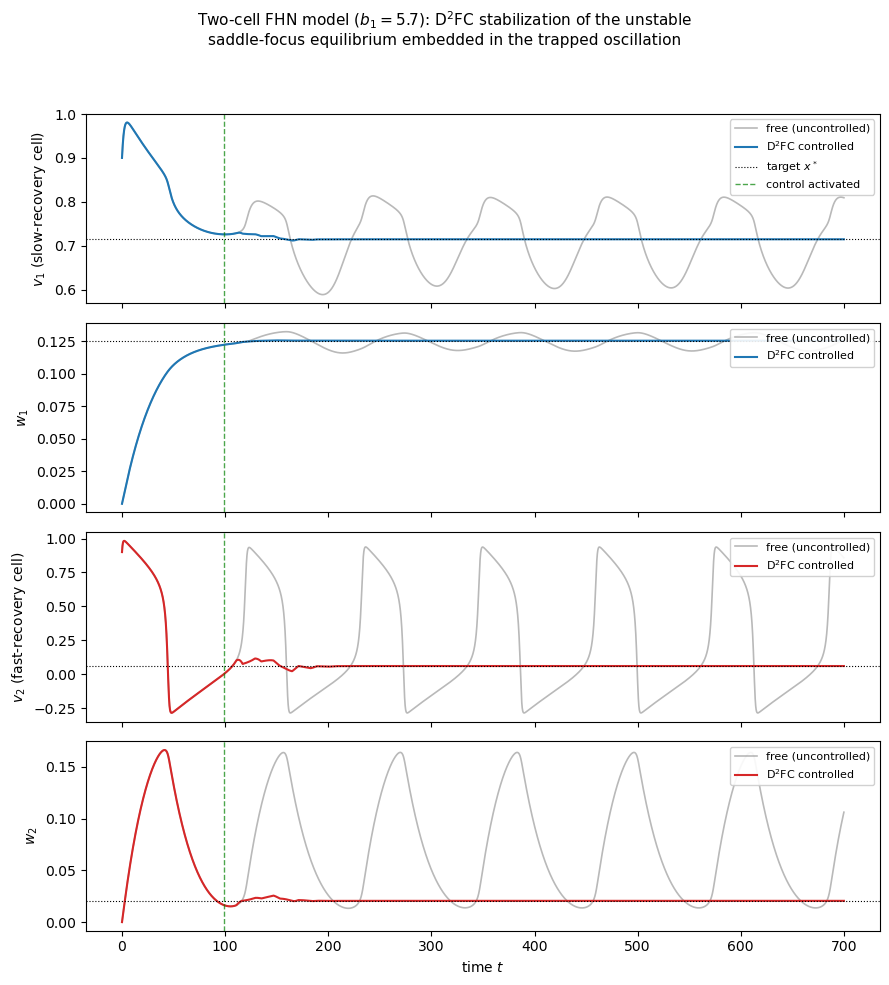

In [10]:
labels = [r'$v_1$ (slow-recovery cell)', r'$w_1$', r'$v_2$ (fast-recovery cell)', r'$w_2$']
colors = ['#1f77b4', '#1f77b4', '#d62728', '#d62728']

fig, axes = plt.subplots(4, 1, figsize=(9, 10), sharex=True)
for i in range(4):
    axes[i].plot(T_free, X_free[:, i], color='gray', alpha=0.55, lw=1.2, label='free (uncontrolled)')
    axes[i].plot(T_ctrl, X_ctrl[:, i], color=colors[i], lw=1.5, label='D$^2$FC controlled')
    axes[i].axhline(xstar[i], color='black', lw=0.8, ls=':', label=r'target $x^*$' if i==0 else None)
    axes[i].axvline(tstar, color='green', lw=1.0, ls='--', alpha=0.7, label='control activated' if i==0 else None)
    axes[i].set_ylabel(labels[i])
    axes[i].legend(loc='upper right', fontsize=8, framealpha=0.9)
axes[-1].set_xlabel('time $t$')
fig.suptitle("Two-cell FHN model ($b_1=5.7$): D$^2$FC stabilization of the unstable\nsaddle-focus equilibrium embedded in the trapped oscillation", fontsize=11)
fig.tight_layout(rect=[0,0,1,0.95])
plt.show()

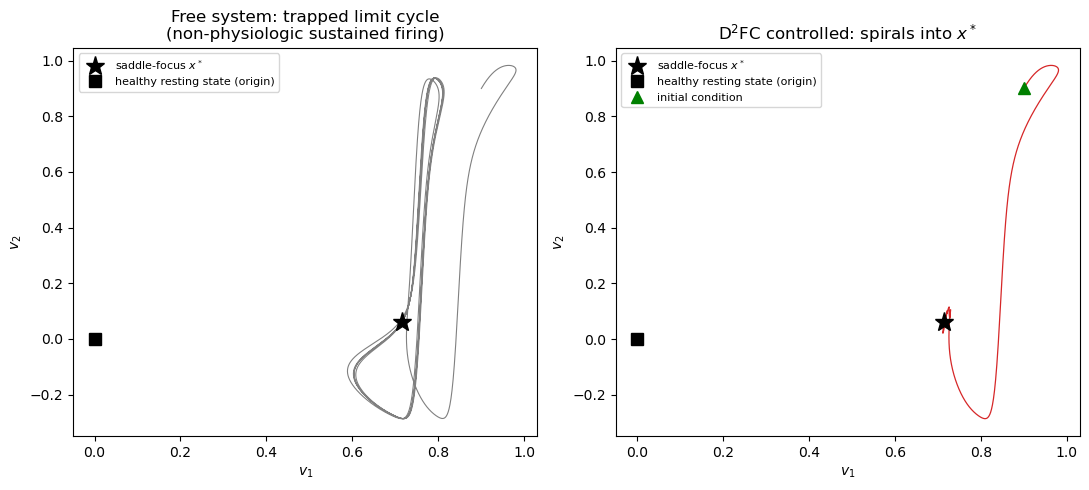

In [11]:
fig2, ax2 = plt.subplots(1, 2, figsize=(11,5))
ax2[0].plot(X_free[:,0], X_free[:,2], color='gray', lw=0.8)
ax2[0].plot(xstar[0], xstar[2], 'k*', ms=14, label=r'saddle-focus $x^*$')
ax2[0].plot(0,0,'ks', ms=8, label='healthy resting state (origin)')
ax2[0].set_xlabel('$v_1$'); ax2[0].set_ylabel('$v_2$')
ax2[0].set_title('Free system: trapped limit cycle\n(non-physiologic sustained firing)')
ax2[0].legend(fontsize=8)

ax2[1].plot(X_ctrl[:,0], X_ctrl[:,2], color='#d62728', lw=0.9)
ax2[1].plot(xstar[0], xstar[2], 'k*', ms=14, label=r'saddle-focus $x^*$')
ax2[1].plot(0,0,'ks', ms=8, label='healthy resting state (origin)')
ax2[1].plot(X_ctrl[0,0], X_ctrl[0,2], 'g^', ms=9, label='initial condition')
ax2[1].set_xlabel('$v_1$'); ax2[1].set_ylabel('$v_2$')
ax2[1].set_title(r'D$^2$FC controlled: spirals into $x^*$')
ax2[1].legend(fontsize=8)
fig2.tight_layout()
plt.show()

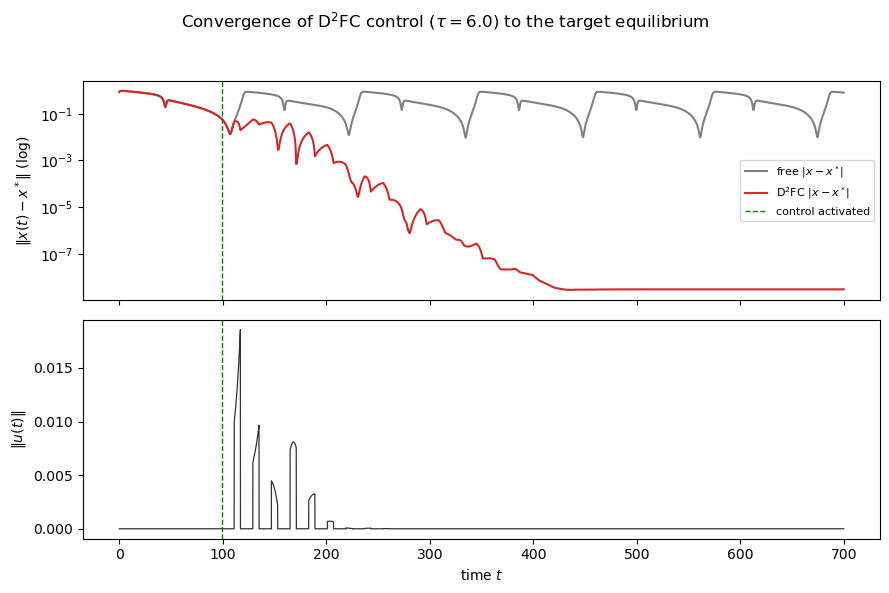

In [12]:
u_ctrl = np.zeros_like(X_ctrl)
delay1 = int(round(tau/dt)); delay2 = int(round(2*tau/dt))
for n in range(len(T_ctrl)):
    t = T_ctrl[n]
    n1, n2 = n-delay1, n-delay2
    xd1 = X_ctrl[n1] if n1>=0 else X_ctrl[0]
    xd2 = X_ctrl[n2] if n2>=0 else X_ctrl[0]
    u_ctrl[n] = Kt_gain(t, tstar) @ (xd2 - xd1)
u_norm = np.linalg.norm(u_ctrl, axis=1)

fig3, ax3 = plt.subplots(2,1, figsize=(9,6), sharex=True)
ax3[0].semilogy(T_free, err_free+1e-12, color='gray', label='free $|x-x^*|$')
ax3[0].semilogy(T_ctrl, err_ctrl+1e-12, color='#d62728', label=r'D$^2$FC $|x-x^*|$')
ax3[0].axvline(tstar, color='green', ls='--', lw=1, label='control activated')
ax3[0].set_ylabel(r'$\|x(t)-x^*\|$ (log)')
ax3[0].legend(fontsize=8)
ax3[1].plot(T_ctrl, u_norm, color='#333333', lw=0.9)
ax3[1].axvline(tstar, color='green', ls='--', lw=1)
ax3[1].set_ylabel(r'$\|u(t)\|$')
ax3[1].set_xlabel('time $t$')
fig3.suptitle(f'Convergence of D$^2$FC control ($\\tau={tau}$) to the target equilibrium')
fig3.tight_layout(rect=[0,0,1,0.95])
plt.show()

## 5. Notes / things to try next

- **Try other equilibria**: swap `xstar` for the lower-branch equilibrium (1 real unstable eigenvalue + 1 stable real + 1 stable complex pair — mixes §3.1 Case 1 and Case 3 formulas) to see the $n_r>0$ branch of §3.2 in action.
- **Vary $b_1$**: increasing $b_1$ deepens the trapped limit cycle (larger basin, per the FHN paper's Fig. 6/12 heat maps) — re-run the design to see how large $\rho$/small $\tau$ needs to be to still pull the trajectory in.
- **Scale up**: the FHN paper's real result is on a 41×41 network grid (their Fig. 4/5), not a 2-cell reduction — extending D²FC there means picking one "sensing" unstable mode of a much higher-dimensional linearization, which the paper's Section 3.2 formalism supports in principle but is a much bigger numerical undertaking.
- **UPO stabilization proper**: if you want to try the D²FC paper's own *sketched-but-unproven* extension for periodic orbits, $u(t)=K(t)[x(t-2T)-x(t-T)]$ with $T$ the limit cycle's period, that would need a Floquet-based redesign — happy to build that as a follow-up.
